# More adventures in Bayes-land

## Introduction

I am still continuing my adventures with Bayesian statistical processing, and in this post, I explore linear model analysis.

Back a little while ago, I discussed fitting different models to my weight loss / diet journey (https://coolum001.github.io/funminim.html). I though I would use the same dataset.  I wound up having to use Claude to debug the ArViz libraries.

## Implementation

### Imports

    ArviZ is a modular and flexible Python library ... providing robust, interpretable diagnostics and visualizations for Bayesian workflow

    PyMC is a probabilistic programming library for Python that allows users to build Bayesian models with a simple Python API and fit them using state of the art algorithms such as Markov chain Monte Carlo (MCMC) methods and variational inference

    PyTensor is a Python library that allows you to define, optimize/rewrite, and evaluate mathematical expressions involving multi-dimensional arrays efficiently

    Xarray is an open-source Python library that makes working with labeled, multi-dimensional arrays and datasets simple, fast, and efficient

In fact, I only import pytensor so I can configure it to work around what (I think) is a problem in my environment

In [188]:
import pathlib

import arviz as az
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pymc as pm
import pytensor
import xarray as xr

-------------------------

### Configure PyTensor

I turn off the feature where an efficient C program is built and compiled.  My baby problems don't need this, and it appears I have a set of clashing C compilers / libraries in my environment

In [189]:
pytensor.config.cxx = ""

### Load dataset

Load the data, and perform a quick and dirty visualization. Superficially, it looks linear

In [190]:
path = pathlib.Path("data/diet_results.xlsx")
df = pd.read_excel(
    path,
    sheet_name="Data Entry",
    usecols=[3, 4],
    skiprows=2,
    nrows=141,
    names=["day", "weight"],
)

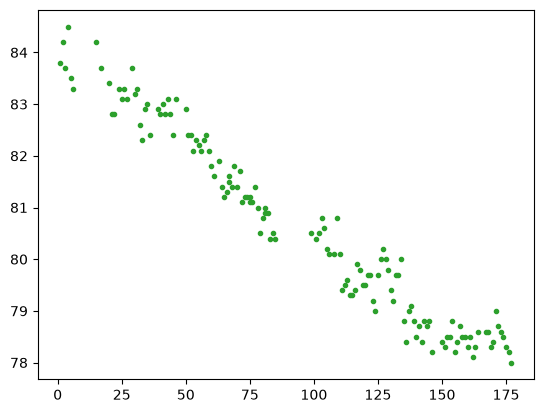

In [191]:
plt.plot(df.day, df.weight, "C2.")

---------------------
### Build model

To start, we specify:

- intercept: a Normal distribution, with a very wide standard deviation.  In practice, we can see the intercept is about 84, so maybe could have set $\mu = 84$, and set a smaller $\sigma$ value. However _pymc_ seems up to the task of handling uninformative priors
- slope: a Normal distribution, with a smaller standard deviation.  In practice, we can tell by eye that the slope is negative (maybe about $-80/200 = -0.04$), so again maybe we could move the prior mean to be smaller than 0.
- error_sd: the standard deviation that jitters our data points away from the "true" straight line. This will be positive, and we allow for large values (Cauchy has a fat tail)
- w_err0: is a computed value: given our intercept and slope, we compute that value in the case where the error term goes to 0
- w_pred: the predicted values. We assume the predicted values will be a Normal, centered on the stright line, with an error standard deviation taken from the HalfCauchy

We just run the default sampling regime. We ignore (because we are in Windows) the message about clashing libraries

In [192]:
with pm.Model() as shift_model:
    intercept = pm.Normal("intercept", mu=0, sigma=100)
    slope = pm.Normal("slope", mu=0, sigma=10)
    error_sd = pm.HalfCauchy("error_sd", beta=10)
    w_err0 = pm.Deterministic("mu", intercept + slope * df.day)
    w_pred = pm.Normal("w_pred", mu=w_err0, sigma=error_sd, observed=df.weight)
    idata = pm.sample()
# end with

C:\Users\donrc\anaconda3\envs\bayes_env\Lib\site-packages\threadpoolctl.py:1226: RuntimeWarning: 
Found Intel OpenMP ('libiomp') and LLVM OpenMP ('libomp') loaded at
the same time. Both libraries are known to be incompatible and this
can cause random crashes or deadlocks on Linux when loaded in the
same Python program.
Using threadpoolctl may cause crashes or deadlocks. For more
information and possible workarounds, please see
    https://github.com/joblib/threadpoolctl/blob/master/multiple_openmp.md

  warnings.warn(msg, RuntimeWarning)
NUTS[nutpie]: [intercept, slope, error_sd]


Output()

### Model initial assessment

First up, we look to see if there is anything obviously bad (in this case, no)

In [193]:
problems = az.diagnose(idata)

Divergences
No divergent transitions found.

E-BFMI
E-BFMI satisfactory for all chains.

ESS
Effective sample size satisfactory for all parameters.

R-hat
R-hat values satisfactory for all parameters.

Processing complete, no problems detected.


We get a summary of our linear model parameters.  The values agree with our eyeball fit

In [194]:
az.summary(
    idata, kind="stats", ci_kind="hdi", var_names=["intercept", "slope", "error_sd"]
)

,mean,sd,hdi89_lb,hdi89_ub
intercept,84,0.07,84,84
slope,-0.035,0.00065,-0.036,-0.034
error_sd,0.39,0.023,0.35,0.43


Finally we check that our model diagram matches what we thought we specified (it does)

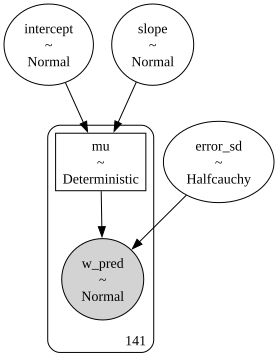

In [195]:
pm.model_to_graphviz(shift_model)

-----------------
### Model detailed assessment

We then look at the Trace plots to check the the randomly sampling behaviour is nominal (it is)

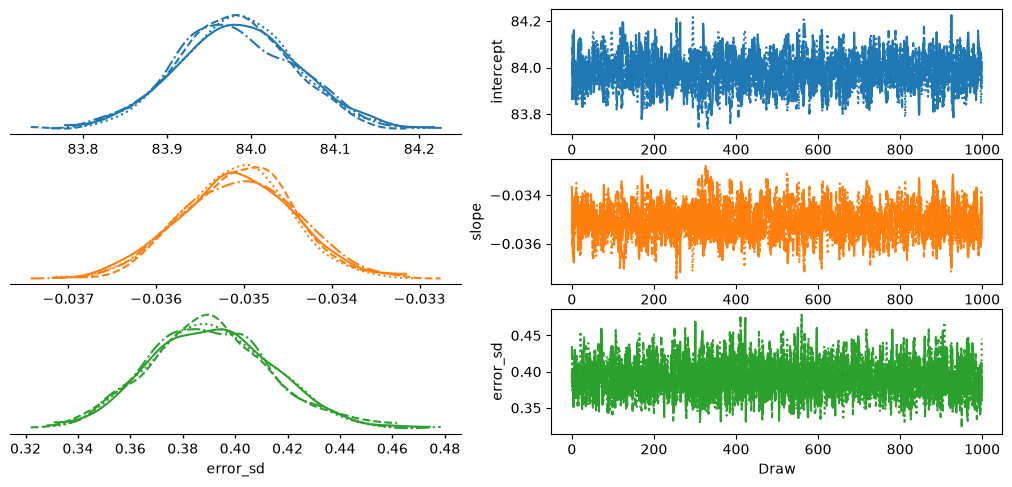

In [196]:
az.plot_trace_dist(idata, var_names=["intercept", "slope", "error_sd"])

Next we check the different values for the Point Estimators.  I think because our model distributions are Normals, and hence symmetric, the various Point Estimators agree closely (I had to bump up the default decimals displayed to see any differences).  Just for fun, I declared (for the mean Point Estimator) that I expected that the _intercept_ estimate should lie between 83.9 and 84.1. Indeed, over 90% of the 89% High Density Interval for _intercept_ values falls in this region.

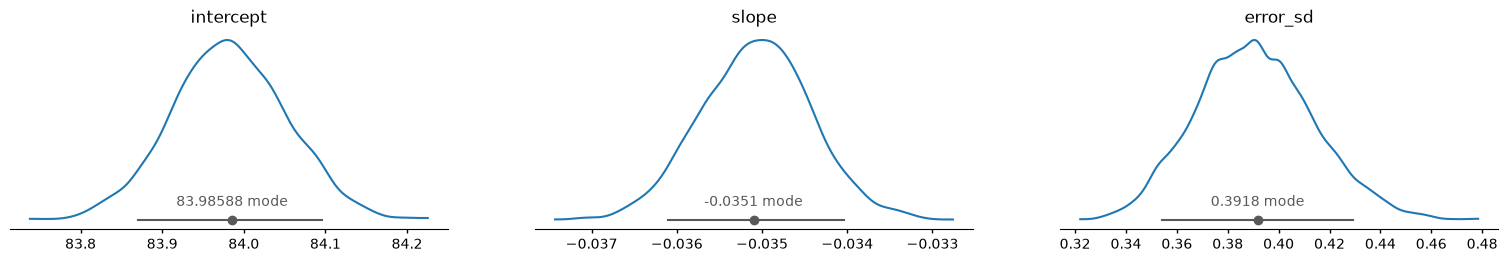

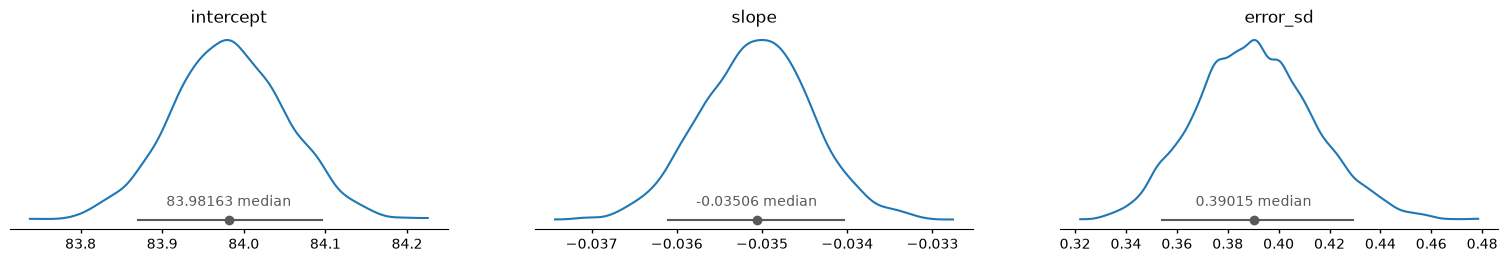

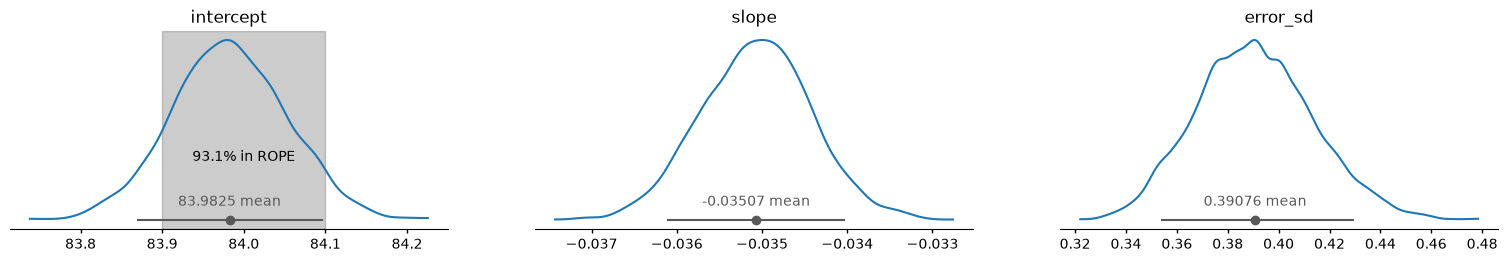

In [197]:
az.plot_dist(
    idata,
    var_names=["intercept", "slope", "error_sd"],
    point_estimate="mode",
    visuals={"point_estimate_text": {"round_to": 5}},
)
az.plot_dist(
    idata,
    var_names=["intercept", "slope", "error_sd"],
    point_estimate="median",
    visuals={"point_estimate_text": {"round_to": 5}},
)
az.plot_dist(
    idata,
    var_names=["intercept", "slope", "error_sd"],
    point_estimate="mean",
    visuals={"point_estimate_text": {"round_to": 5}},
    rope={"intercept": (83.9, 84.1)},
)

Generate additional results from our model: to quote -

    This method can be used to perform different kinds of model predictions, including posterior predictive checks.

In [198]:
with shift_model:
    pm.sample_posterior_predictive(idata, extend_inferencedata=True)

Sampling: [w_pred]


Output()

### Distribution of predictions

We can use a specialized __ArViz__ plot to show how the predictions the model makes agree with the observed data.  In general the agreement is Ok, except that it under-estimates at low values of weight (around 78 Kg).  If you read my original blog post, indeed anomalous events occured at the end of my diet (I got slack and started eating again!)

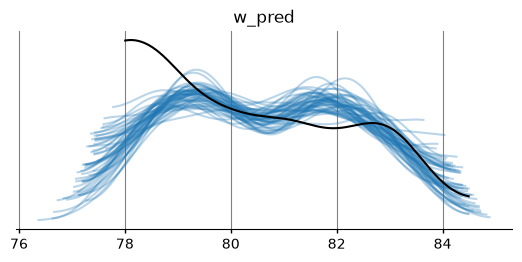

In [203]:
pc = az.plot_ppc_dist(idata, kind="auto")

pc.map(
    az.visuals.grid,
    axis="x",
    color="gray",
)

Plot_Pair allows us the look at the correlation of our slope and intercept estimates

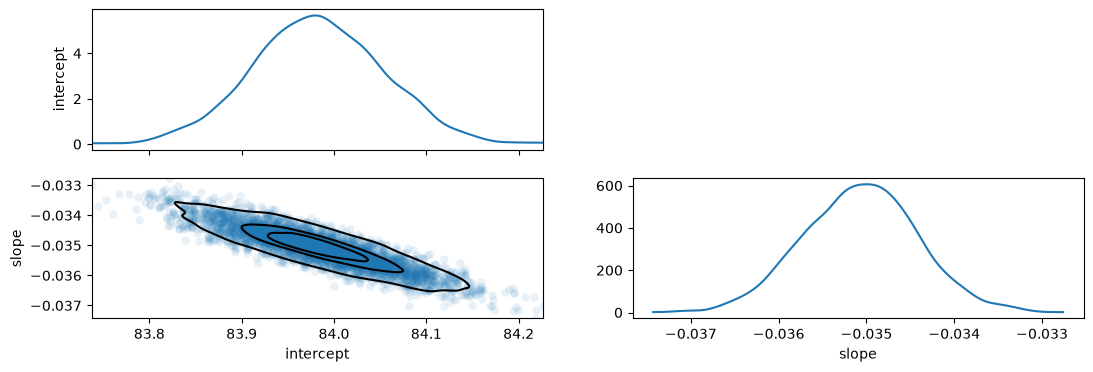

In [204]:
az.plot_pair(
    idata,
    var_names=["intercept", "slope"],
    visuals={
        "divergence": False,
        "contour": True,
        "scatter": {"alpha": 0.1},
    },
)

---------------

### Graphic Production

It was at this stage that I started to wrestle with __ArviZ__ in earnest.  There is a function _plot_lm_
that takes our model, and produces a standard scatter plot and fitted line graphic.  The first attempt to run this was a failure

In [205]:
az.plot_lm(idata, x=None, y=None)

ValueError: x and y must have the same length

It turns out that _plot_lm_ goes to our model data structure, and extracts the data it needs to build a plot.  We need to update the _constant_data_ part of the data structure with our x axis values (here, days into my diet).  The dimension names (an _xarray_ concept) have to match the dimension name of the y axis data (actual and prredicted weight). To quote from the documentation of _plot_lm_

    x: Independent variable. If None, use the first variable in group. Data will be taken from the constant_data group 

In [206]:
x_data = xr.DataArray(df.day, dims=["w_pred_dim_0"])
idata["constant_data"]["day"] = x_data

------------

#### Default _plot_lm_ outout

Now we are in a position to create our first graphic

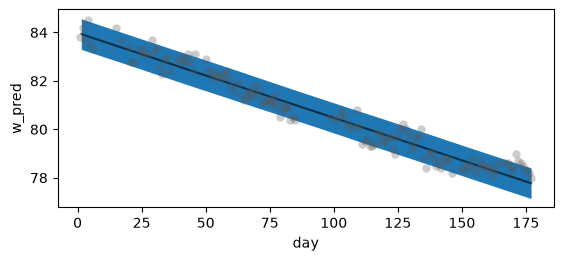

In [207]:
pc = az.plot_lm(
    idata,
)

#### Enhance plot appearence

The graphic above is pretty drab. To improve we

- make confidence interval band more transparent
- enhance the scatter plot
- set the figure size
- set confidence interval to 95% High Density Interval
- add a marker kine for 78 Kg, final target weight
- add a grid
- label the Axes
- set a Title

The code fragment ```pc.viz.figure.item().axes[0]``` says "from the arviz PlotCollection object, get the _viz_ attribute, get the _matplotlib_ _figure_ object reference, then get the actual _figure_ object, and then get the first _matplotlib_ _Axes_ object.  Occasionaly you have to dive down to _matplotlib_ calls to achieve a desired graphic

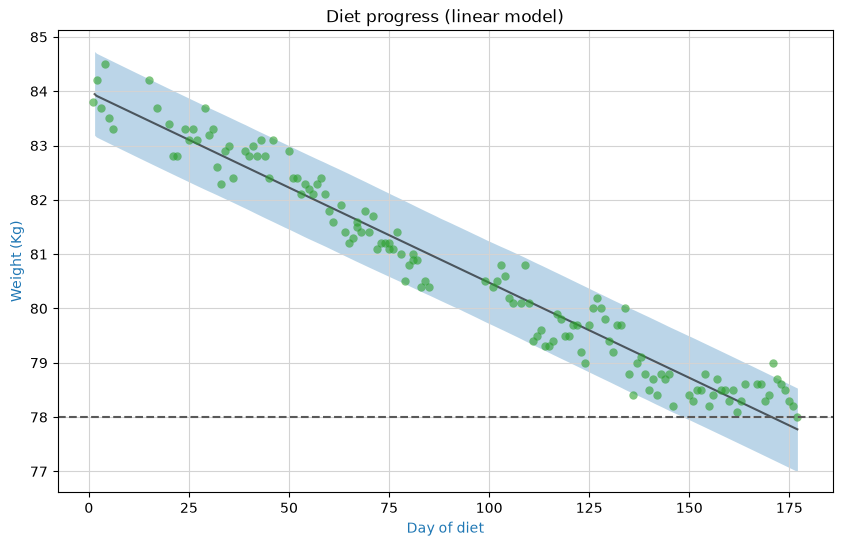

In [210]:
# do a linear model plot
# set Confidence Interval band  0.3 transparent
# set the scatter plot points to green, and make partially transparent
# set the figure size
# set the confidence interval type to HDI (High Density Interval)
# set the HDI band to contain 95% of estimated prob. densit
pc = az.plot_lm(
    idata,
    visuals={
        "ci_band": {"alpha": 0.3},
        "observed_scatter": {"color": "C2", "alpha": 0.6},
    },
    figure_kwargs={"figsize": (10, 6)},
    ci_kind="hdi",
    ci_prob=0.95,
)

# add a horizontal line for diet target weight
az.add_lines(pc, orientation="horizontal", values=[78])

# add a pale grid
pc.map(
    az.visuals.grid,
    axis="both",
    color="lightgray",
)

# label x axis
pc.map(
    az.visuals.labelled_x,
    text="Day of diet",
)
# label y axis
pc.map(
    az.visuals.labelled_y,
    text="Weight (Kg)",
)


_ = pc.viz.figure.item().axes[0].set_title("Diet progress (linear model)")

--------------------
### Plotting grid of figures

I became interested to see if I coulld tell the difference between the various Point Estimators, so I created three plots, as below

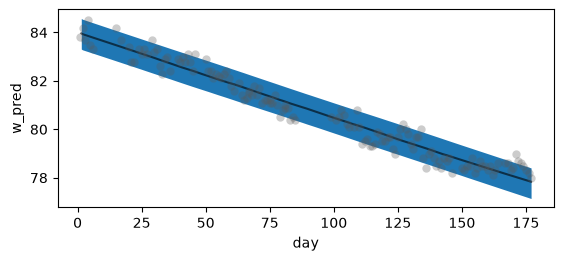

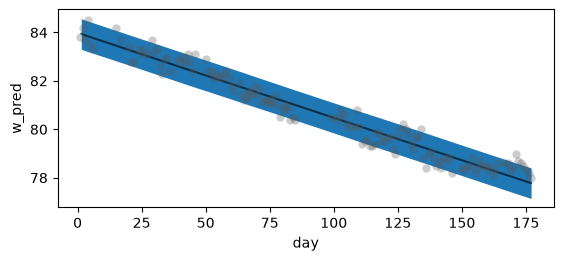

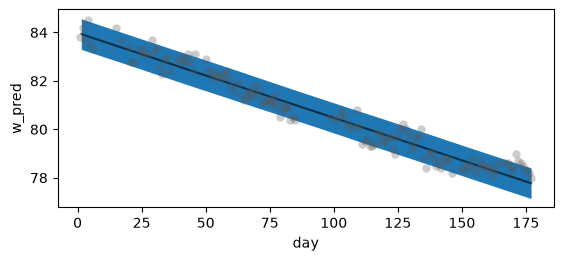

In [213]:

pc1 = az.plot_lm(
    idata,
    point_estimate="mode",
)
pc2 = az.plot_lm(
    idata,
    point_estimate="median",
)
pc3 = az.plot_lm(
    idata,
    point_estimate="mean",
)

I was unhappy with the results above, as I really wanted the plots to be side by side.  This lead me to the _PlotCollection.grid()_ method.  It turns out that the obvious function to use (_combine_plots()_ ) flows calling parameters down in a way that is incompatable with _plot_lm()_.
Again, we have to augment our model simulation data structure, with a new dimension to our _constant_data_ group, and a set of value along that dimension(being our Point Estimate names).

We create a grid of PlotCollections, column-wise (i.e. side-by-side), each using _matplotlib_ as the backend plotting engine, and also set the _matplotlib_ Figure size, and nominate that each plot will share the y axis tick-marks

Then we loop over Point Estimator names, using each name to reference a PlotCollection in our grid (```pc.coords = {"column": pe}```.  With this PlotCollection reference, we create our plot

Then we have another loop that adds a title to each PlotCollection object (```pc.get_target("x", {"column": pe}).set_title(pe)```).

The ```pc.map``` calls set the nominated visual attribute of all the PlotCollections in our grid.

Then finally we dip down into _matplotlib_ again, to label the left-most y axis.  We had cleared all Y axis labels in the _plot_lm_ calls above (```"ylabel": False,```)

Text(0, 0.5, 'Weight (Kg)')

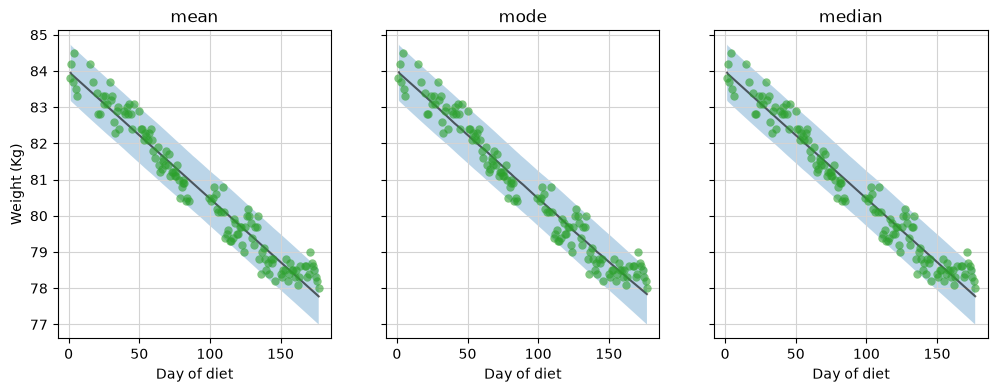

In [215]:
estimates = ["mean", "mode", "median"]

# grid built from the x variable (constant_data), with one column per estimate
x_data = idata["constant_data"].dataset.expand_dims(column=estimates)


pc = az.PlotCollection.grid(
    x_data,
    backend="matplotlib",
    cols=["column"],
    figure_kwargs={"figsize": (12, 4), "sharey": True},
)

for pe in estimates:
    pc.coords = {"column": pe}  # draw the next call into this column
    az.plot_lm(
        idata,
        point_estimate=pe,
        plot_collection=pc,
        visuals={
            "ci_band": {"alpha": 0.3},
            "observed_scatter": {"color": "C2", "alpha": 0.6},
            "ylabel": False,
        },
        figure_kwargs={"figsize": (10, 6)},
        ci_kind="hdi",
        ci_prob=0.95,
    )
#end for

pc.coords = None

# optional: label each panel
for pe in estimates:
    # matplotlib call
    pc.get_target("x", {"column": pe}).set_title(pe)
# end for

# set the grid and label the x axis in all our plots
pc.map(
    az.visuals.grid,
    axis="both",
    color="lightgray",
)
pc.map(
    az.visuals.labelled_x,
    text="Day of diet",
)
pc.get_target("x", {"column": estimates[0]}).set_ylabel("Weight (Kg)")

Success! of course I can't tell the difference between plots, but as a learning exercise it was worth it.

-------------------------------------
### Adding a legend

The only thing missing from the big plot above was a legend

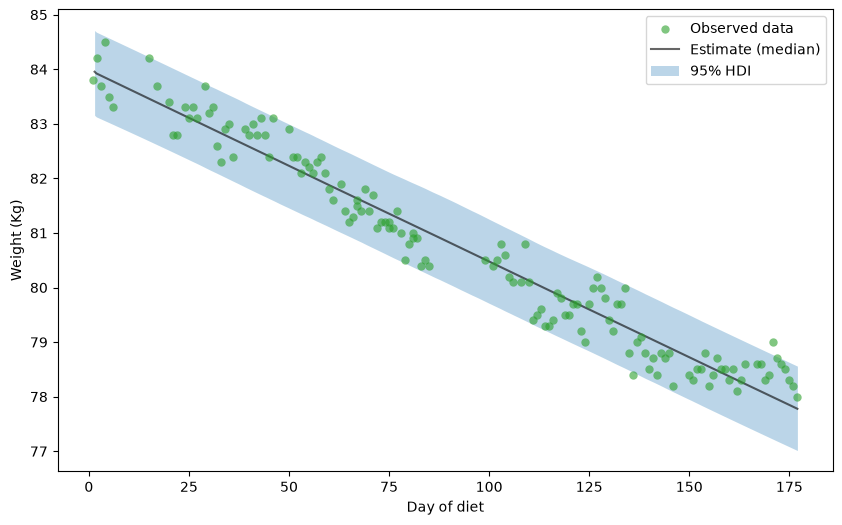

In [183]:

# chosen Point Estimator to illustrate legends
pe = "median"

# create PlotCollection object with a plot in it
pc2 = az.plot_lm(
    idata,
    point_estimate=pe,
    # plot_collection=pc,
    visuals={
        "ci_band": {"alpha": 0.3},
        "observed_scatter": {"color": "C2", "alpha": 0.6},
    },
    figure_kwargs={"figsize": (10, 6)},
    ci_kind="hdi",
    ci_prob=0.95,
)

# get matplotlib reference and  set axis labels
_ = pc2.get_target("day", {}).set_ylabel("Weight (Kg)")
_ = pc2.get_target("day", {}).set_xlabel("Day of diet")

ax = pc2.get_target("day", {})  # get Axes objct reference

# get the visual items that we want to appear in our legend
obs = pc2.viz["observed_scatter"]["day"].item()  # scatter of observed data
line = pc2.viz["pe_line"]["day"].item()  # point-estimate line
band = pc2.viz["ci_band"]["day"].item()  # credible-interval band

# values to appear in legend text
ci_prob = 0.95
ci_kind = "hdi"

# use legend(handles, labels) type of legend creation call
ax.legend(
    [obs, line, band],
    ["Observed data", f"Estimate ({pe})", f"{ci_prob:.0%} {ci_kind.upper()}"],
    loc="best",
)

### Gotcha 
You cant just re-use a PlotCollection object in a Jupyter Notebook cell below where it was created

    Because arviz_plots uses Matplotlib under the hood by default, your PlotCollection object (pc) still holds references to the underlying figure and axes, but Matplotlib has already rendered it and cleared it from its active memory buffer. Calling pc.show() in a subsequent cell targets a closed figure, resulting in no output

We get the Figure object, and execute that

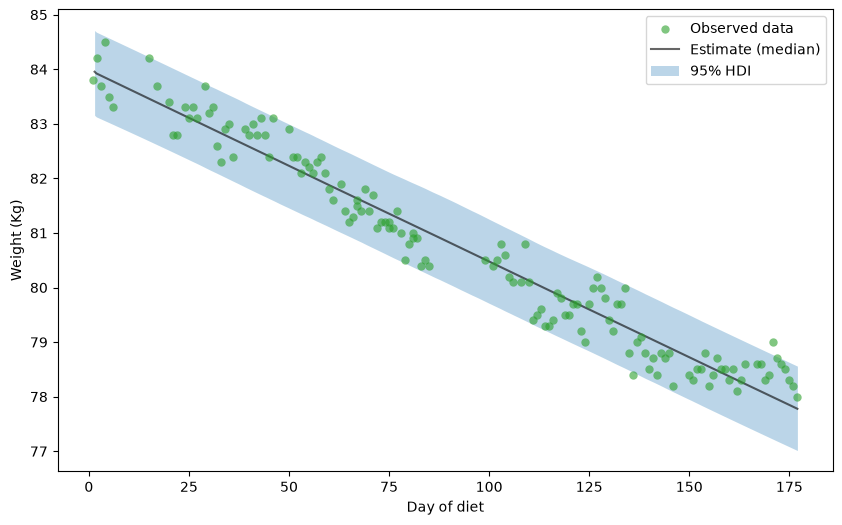

In [184]:
pc2.viz["figure"].values.item()

----------------------
## Conclusion

I sort of miss the ability to draw Mean and Instance Confidence Intervals easily on a graph:  a lot of very heavy machinery was deployed to get the results above.  However it was worth it for  the change of mindset on seeing the distributions of the _intercept_ and _slope_ (rather than fixed numbers).

My next setp will be to look at models with kinks in the fitted line (change of slopes in the line of best fit.

--------------------

## Reproducability

In [96]:
%load_ext watermark

In [97]:
%watermark

Last updated: 2026-09-21T15:11:15.339281+10:00

Python implementation: CPython
Python version       : 3.14.7
IPython version      : 9.17.1

Compiler    : MSC v.1944 64 bit (AMD64)
OS          : Windows
Release     : 11
Machine     : AMD64
Processor   : Intel64 Family 6 Model 170 Stepping 4, GenuineIntel
CPU cores   : 22
Architecture: 64bit



In [98]:
%watermark -h -iv -co

conda environment: bayes_env

Hostname: INSPIRON16

arviz     : 1.3.0
matplotlib: 3.11.1
numpy     : 2.4.6
pandas    : 3.0.5
preliz    : 0.28.0
pymc      : 6.3.1
pytensor  : 3.3.0
xarray    : 2026.7.0

